# Chapitre 10 - Cours 3 : MapReduce, le shuffle et les jointures

MapReduce a rendu le traitement par lots distribué accessible : on écrit deux fonctions,
le framework se charge du reste (découpage, placement, tri distribué, relances).
C'est le modèle central de ce chapitre du livre, implémenté par Hadoop et repris par de nombreux systèmes.
Ce cours construit un MapReduce miniature (`B.run_mapreduce`) qui écrit de vrais
fichiers de shuffle, puis s'en sert pour les jointures et les regroupements. Il couvre
les sections *MapReduce Job Execution* (*Distributed execution of MapReduce*, *MapReduce workflows*), *Reduce-Side Joins and Grouping* (avec *Handling skew*) et *Map-Side Joins*.

**Plan.**

1. Le modèle MapReduce : un mappeur, un réducteur, et un tri entre les deux.
2. L'exécution distribuée : le shuffle, un tri distribué.
3. Enchaîner des jobs MapReduce.
4. Jointures et regroupements côté reduce (jointure tri-fusion).
5. L'asymétrie : clés chaudes et réducteurs à la traîne.
6. Jointures côté map : hachage diffusé, hachage partitionné, fusion.

In [1]:
import json
import os
import subprocess
import sys
import tempfile
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
lines = B.generate_access_log(200_000, n_urls=2000, s=1.1, seed=2)

## 1. Le modèle MapReduce (section *MapReduce Job Execution*)

Un job MapReduce reprend exactement les étapes du pipeline Unix du cours 1 :

1. **lire** les fichiers d'entrée et les découper en enregistrements (une ligne de
   journal) ;
2. appeler le **mappeur** sur chaque enregistrement pour en extraire une clé et une
   valeur (`awk '{print $7}'` : la clé est l'URL, la valeur est vide) ;
3. **trier** tous les couples (clé, valeur) par clé (le premier `sort`) ;
4. appeler le **réducteur** sur les valeurs de chaque clé, désormais adjacentes
   (`uniq -c` compte les lignes égales consécutives).

Le programmeur n'écrit que les étapes 2 et 4. Le mappeur est appelé une fois par
enregistrement, sans garder d'état d'un appel à l'autre, et peut émettre zéro, un ou
plusieurs couples. Le réducteur reçoit une clé et un itérateur sur toutes ses valeurs.
Le tri de l'étape 3 est **implicite** : le framework le fait toujours.

In [2]:
def mappeur_url(ligne):
    yield B.url_of(ligne), 1          # clé = URL, valeur = 1


def reducteur_somme(url, valeurs):
    yield [url, sum(valeurs)]


sorties, compteurs = B.run_mapreduce([lines], mappeur_url, reducteur_somme, n_reducers=1)
top = sorted(sorties[0], key=lambda r: -r[1])[:5]
pd.DataFrame(top, columns=["URL", "requêtes"])

,URL,requêtes
0,/,33988
1,/favicon.ico,15685
2,/2016/06/15/local-crdt.html,10253
3,/2012/01/04/clocks-automerge-consensus.html,7350
4,/2012/08/13/shuffle-byzantine-isolation.html,5692


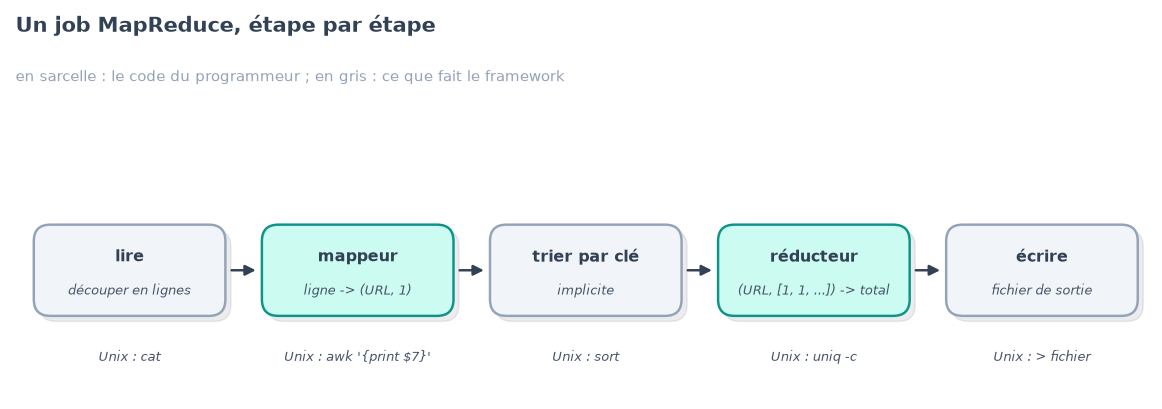

In [3]:
d = Diagram(12.5, 3.3, title="Un job MapReduce, étape par étape",
            subtitle="en sarcelle : le code du programmeur ; en gris : ce que fait le framework")
d.flow([("lire", "lire", "découper en lignes"), ("map", "mappeur", "ligne -> (URL, 1)"),
        ("tri", "trier par clé", "implicite"), ("red", "réducteur", "(URL, [1, 1, ...]) -> total"),
        ("ecr", "écrire", "fichier de sortie")], y=1.4, x0=1.3, dx=2.5, w=2.1, h=1.0,
       colors=[GRAY, TEAL, GRAY, TEAL, GRAY])
for x, t in [(1.3, "cat"), (3.8, "awk '{print $7}'"), (6.3, "sort"), (8.8, "uniq -c"), (11.3, "> fichier")]:
    d.note(x, 0.45, f"Unix : {t}", fontsize=8.5)
d.show()

**Pourquoi c'est parallélisable : la programmation fonctionnelle.** Les noms viennent des
fonctions d'ordre supérieur `map` et `reduce` (ou *fold*) de Lisp. Comme chaque appel au
mappeur ou au réducteur ne dépend que de ce que le framework lui passe (pas d'état
partagé, pas d'effet de bord), le framework est libre de lancer les appels en parallèle
sur des machines différentes, et de **rejouer** un appel ailleurs si une tâche échoue.
Le top 5 trié par nombre décroissant exige un second tri : en MapReduce, c'est un second
job (section 3).

> **À retenir.** MapReduce = mappeur (extraire une clé) + tri implicite par clé +
> réducteur (traiter chaque groupe). Des fonctions sans état ni effet de bord permettent
> au framework de paralléliser et de rejouer les tâches librement.

## 2. L'exécution distribuée : le shuffle (section *Distributed execution of MapReduce*)

L'entrée est **partitionnée** : un fichier par morceau (ou un bloc du DFS). Le framework
lance une **tâche map** par morceau d'entrée ; le nombre de **tâches reduce** est choisi
par l'auteur du job. Pour que toutes les valeurs d'une même clé arrivent au même
réducteur, chaque mappeur écrit, sur son **disque local**, un fichier par réducteur : le
couple (clé, valeur) va dans le fichier du réducteur `hash(clé) mod R` (le
partitionnement par hachage du chapitre 6). Chaque fichier est **trié par
clé** pendant son écriture (tri en mémoire puis fusion de segments, comme au cours 1).
Quand un mappeur a fini, chaque réducteur vient chercher **son** fichier, puis fusionne
les fichiers de tous les mappeurs en préservant l'ordre : les valeurs d'une même clé sont
alors consécutives, même venues de mappeurs différents. Cette répartition puis ce tri
distribués forment le **shuffle**. Malgré son nom (« battre les cartes »), il n'a rien
d'aléatoire : il produit un ordre trié.

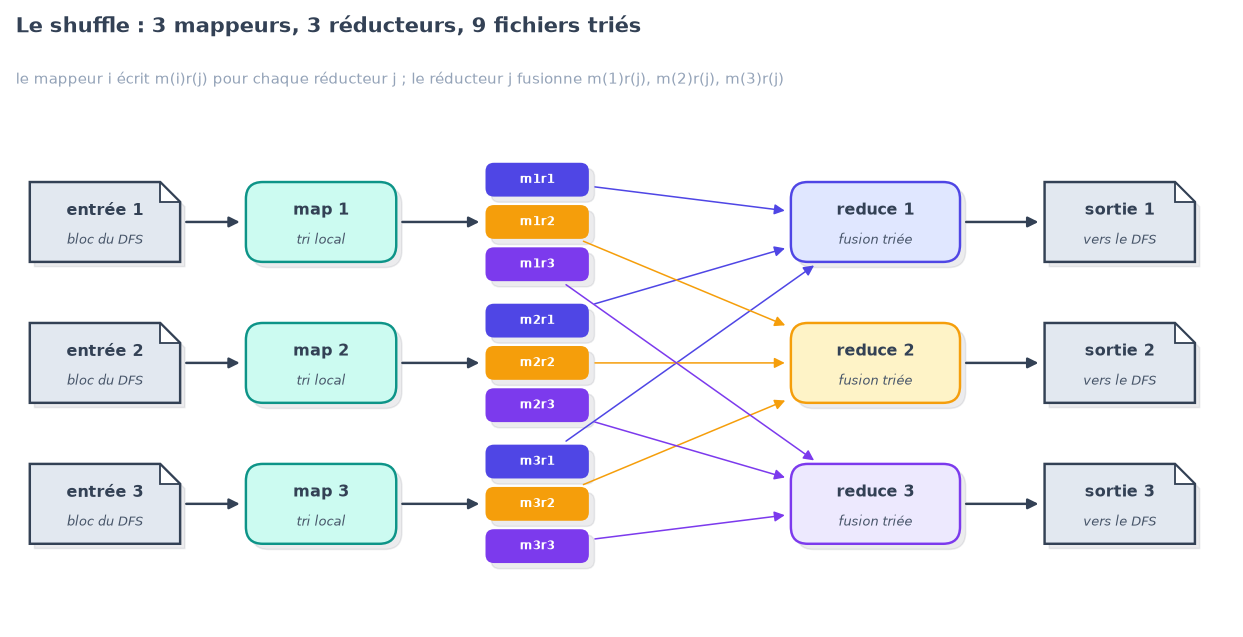

In [4]:
d = Diagram(13, 5.6, title="Le shuffle : 3 mappeurs, 3 réducteurs, 9 fichiers triés",
            subtitle="le mappeur i écrit m(i)r(j) pour chaque réducteur j ; le réducteur j fusionne m(1)r(j), m(2)r(j), m(3)r(j)")
for i in range(3):
    y = 4.3 - 1.5 * i
    d.box(f"in{i}", 1.0, y, f"entrée {i + 1}", sub="bloc du DFS", color=SLATE, kind="doc", w=1.6, h=0.85)
    d.box(f"m{i}", 3.3, y, f"map {i + 1}", sub="tri local", color=TEAL, w=1.6, h=0.85)
    d.arrow(f"in{i}", f"m{i}", "")
    for j in range(3):
        d.box(f"f{i}{j}", 5.6 + 0.0 * j, y + 0.45 - 0.45 * j, f"m{i + 1}r{j + 1}", color=[INDIGO, AMBER, VIOLET][j],
              w=1.1, h=0.36, fontsize=8, kind="tag")
    d.arrow(f"m{i}", f"f{i}1", "")
for j in range(3):
    y = 4.3 - 1.5 * j
    d.box(f"r{j}", 9.2, y, f"reduce {j + 1}", sub="fusion triée", color=[INDIGO, AMBER, VIOLET][j], w=1.8, h=0.85)
    d.box(f"o{j}", 11.8, y, f"sortie {j + 1}", sub="vers le DFS", color=SLATE, kind="doc", w=1.6, h=0.85)
    d.arrow(f"r{j}", f"o{j}", "")
    for i in range(3):
        d.arrow(f"f{i}{j}", f"r{j}", "", color=[INDIGO, AMBER, VIOLET][j], lw=1.0)
d.show()

Exécutons le job de comptage avec 4 mappeurs et 3 réducteurs en conservant les fichiers
intermédiaires, pour regarder ce que contient chacun d'eux.

début de m1_r2.jsonl (trié par clé) :
  ["/2010/01/01/index-replication.html", 1]
  ["/2010/01/13/ethics-fencing-isolation.html", 1]
  ["/2010/01/13/ethics-fencing-isolation.html", 1]


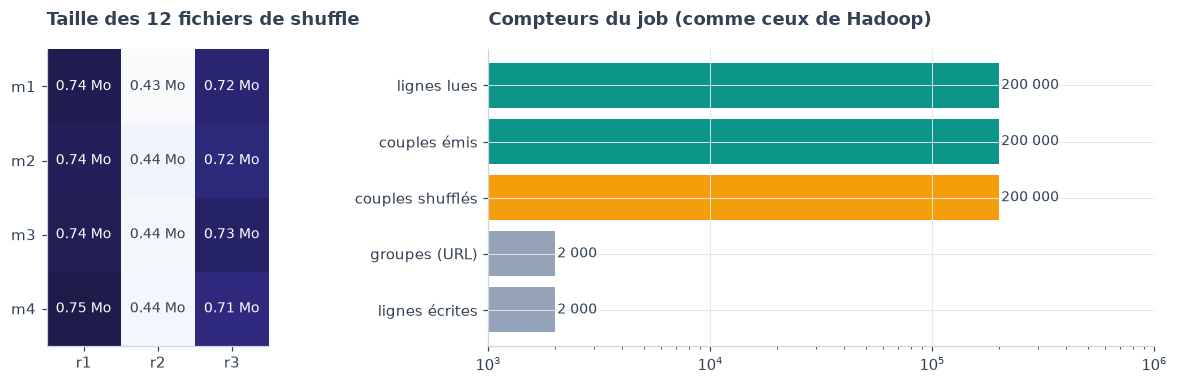

In [5]:
shards = [lines[i::4] for i in range(4)]
WORK = tempfile.mkdtemp(prefix="ddia_mr_")
sorties, st = B.run_mapreduce(shards, mappeur_url, reducteur_somme, n_reducers=3, workdir=WORK)
fichiers = sorted(f for f in os.listdir(WORK) if f.startswith("m"))
taille = np.zeros((4, 3))
for f in fichiers:
    i, j = int(f[1]) - 1, int(f[4]) - 1
    taille[i, j] = os.path.getsize(os.path.join(WORK, f)) / 1e6
with open(os.path.join(WORK, "m1_r2.jsonl")) as f:
    extrait = [next(f).strip() for _ in range(3)]
print("début de m1_r2.jsonl (trié par clé) :", *extrait, sep="\n  ")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})
im = axes[0].imshow(taille, cmap="ddia_seq")
for i in range(4):
    for j in range(3):
        axes[0].text(j, i, f"{taille[i, j]:.2f} Mo", ha="center", va="center", fontsize=9,
                     color="white" if taille[i, j] > taille.max() * 0.6 else SLATE)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels([f"r{j + 1}" for j in range(3)])
axes[0].set_yticks(range(4)); axes[0].set_yticklabels([f"m{i + 1}" for i in range(4)])
axes[0].grid(False); axes[0].set_title("Taille des 12 fichiers de shuffle")
cpt = pd.Series({"lignes lues": st.map_input_records, "couples émis": st.map_output_records,
                 "couples shufflés": st.shuffle_records, "groupes (URL)": st.reduce_groups,
                 "lignes écrites": st.reduce_output_records})
axes[1].barh(cpt.index[::-1], cpt.values[::-1], color=[GRAY, GRAY, AMBER, TEAL, TEAL])
for k, v in enumerate(cpt.values[::-1]):
    axes[1].text(v * 1.02, k, f"{v:,}".replace(",", " "), va="center", fontsize=9)
axes[1].set_xscale("log"); axes[1].set_xlim(1e3, 1e6)
axes[1].set_title("Compteurs du job (comme ceux de Hadoop)")
plt.tight_layout(); plt.show()

Chaque ligne du journal produit un couple qui traverse le shuffle : 200 000 couples pour
2 000 groupes. Les réducteurs reçoivent des volumes proches, mais pas égaux, car les URL
n'ont pas toutes la même popularité (section 5). L'exercice 10.5 montre comment un
**combineur** (une pré-agrégation côté map) réduit ce volume.

**Un piège de déterminisme.** Le partitionnement doit donner le même réducteur pour la
même clé dans **tous** les processus. Or la fonction `hash` de Python sur les chaînes
est randomisée à chaque lancement de l'interpréteur (variable `PYTHONHASHSEED`), pour se
protéger d'attaques par collisions. Deux mappeurs qui l'utiliseraient enverraient la même
URL à des réducteurs différents, et le comptage serait faux sans aucune erreur visible.
D'où `B.stable_hash` (CRC32 de la clé sérialisée).

In [6]:
code = "import zlib; k='/favicon.ico'; print(hash(k) % 3, zlib.crc32(k.encode()) % 3)"
rows = []
for seed in ["1", "2", "3", "4", "5", "6"]:
    out = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True,
                         env=dict(os.environ, PYTHONHASHSEED=seed)).stdout.split()
    rows.append({"processus (PYTHONHASHSEED)": seed, "hash(k) % 3": int(out[0]), "crc32(k) % 3": int(out[1])})
pd.DataFrame(rows).set_index("processus (PYTHONHASHSEED)").T

processus (PYTHONHASHSEED),1,2,3,4,5,6
hash(k) % 3,2,1,1,1,1,2
crc32(k) % 3,1,1,1,1,1,1


**Le parallélisme.** `processes=k` exécute les tâches map puis reduce dans $k$ processus.
Mesurons l'accélération sur un journal plus gros, en gardant 8 mappeurs et 8 réducteurs.

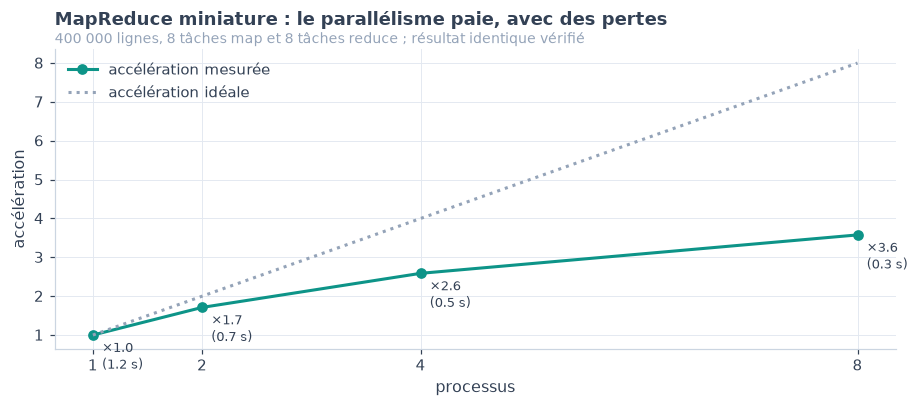

In [7]:
gros = B.generate_access_log(400_000, n_urls=5000, seed=5)
shards8 = [gros[i::8] for i in range(8)]
durees = {}
for p in [1, 2, 4, 8]:
    ts = []
    for _ in range(2):
        t0 = time.perf_counter()
        out_p, _ = B.run_mapreduce(shards8, mappeur_url, reducteur_somme, n_reducers=8, processes=p)
        ts.append(time.perf_counter() - t0)
    durees[p] = min(ts)
ref = sorted(x for o in B.run_mapreduce(shards8, mappeur_url, reducteur_somme, n_reducers=8)[0] for x in o)
assert sorted(x for o in out_p for x in o) == ref
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ps = np.array(list(durees))
acc = durees[1] / np.array(list(durees.values()))
ax.plot(ps, acc, "o-", color=TEAL, label="accélération mesurée")
ax.plot(ps, ps, ":", color=GRAY, label="accélération idéale")
for p_, a_ in zip(ps, acc):
    ax.annotate(f"×{a_:.1f}\n({durees[p_]:.1f} s)", (p_, a_), (6, -22), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("processus"); ax.set_ylabel("accélération")
ax.set_xticks(ps)
ax.set_title("MapReduce miniature : le parallélisme paie, avec des pertes")
subtitle(ax, "400 000 lignes, 8 tâches map et 8 tâches reduce ; résultat identique vérifié")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

L'accélération est réelle mais sous-linéaire : la phase reduce ne commence qu'après la
**dernière** tâche map (barrière), les fichiers intermédiaires sont sérialisés en JSON
et relus, et le lancement des processus a un coût fixe. Ce sont, en petit, les
surcoûts que les moteurs dataflow du cours 4 s'attachent à réduire.

> **À retenir.** Le shuffle est un tri distribué : chaque mappeur partitionne sa sortie
> par hachage de la clé (un fichier trié par réducteur, sur disque local), chaque
> réducteur rapatrie et fusionne ses fichiers. Le partitionnement doit être
> **déterministe** d'un processus à l'autre.

## 3. Enchaîner des jobs MapReduce (section *MapReduce workflows*)

Un job MapReduce ne fait qu'un tri. Pour le top 5 du cours 1, il en faut deux : le job
1 compte les requêtes par URL ; le job 2 relit sa sortie et la trie par nombre
décroissant (clé = moins le nombre, un seul réducteur pour obtenir un ordre global). Dans
Hadoop, la sortie du job 1 est **écrite dans le DFS** (donc répliquée trois fois) avant
que le job 2 ne démarre : c'est le prix de la tolérance aux pannes par matérialisation
(cours 2, section 4).

In [8]:
WORK1, WORK2 = tempfile.mkdtemp(prefix="job1_"), tempfile.mkdtemp(prefix="job2_")
out1, st1 = B.run_mapreduce(shards, mappeur_url, reducteur_somme, n_reducers=3, workdir=WORK1)
taille_inter = sum(os.path.getsize(os.path.join(WORK1, f"r{j + 1}.jsonl")) for j in range(3))


def mappeur_classement(rec):
    url, n = rec
    yield -n, url                      # trier par nombre décroissant


def reducteur_top(moins_n, urls):
    for u in urls:
        yield [u, -moins_n]


out2, st2 = B.run_mapreduce(out1, mappeur_classement, reducteur_top, n_reducers=1, workdir=WORK2)
bilan = pd.DataFrame([
    {"job": "1 : compter par URL", "entrée (enreg.)": st1.map_input_records, "shuffle (enreg.)": st1.shuffle_records,
     "sortie (enreg.)": st1.reduce_output_records},
    {"job": "2 : trier par nombre", "entrée (enreg.)": st2.map_input_records, "shuffle (enreg.)": st2.shuffle_records,
     "sortie (enreg.)": st2.reduce_output_records}]).set_index("job")
print("top 5 :", out2[0][:5])
print(f"sortie intermédiaire du job 1 : {taille_inter / 1e3:.0f} Ko, soit {3 * taille_inter / 1e3:.0f} Ko écrits avec 3 répliques")
bilan

top 5 : [('/', 33988), ('/favicon.ico', 15685), ('/2016/06/15/local-crdt.html', 10253), ('/2012/01/04/clocks-automerge-consensus.html', 7350), ('/2012/08/13/shuffle-byzantine-isolation.html', 5692)]
sortie intermédiaire du job 1 : 97 Ko, soit 290 Ko écrits avec 3 répliques


,entrée (enreg.),shuffle (enreg.),sortie (enreg.)
job,,,
1 : compter par URL,200000,200000,2000
2 : trier par nombre,2000,2000,2000


Le schéma espace-temps montre la contrainte de **matérialisation** : le job 2 attend la
fin du job 1 tout entier, y compris de sa tâche la plus lente, puis relit son entrée
depuis le DFS.

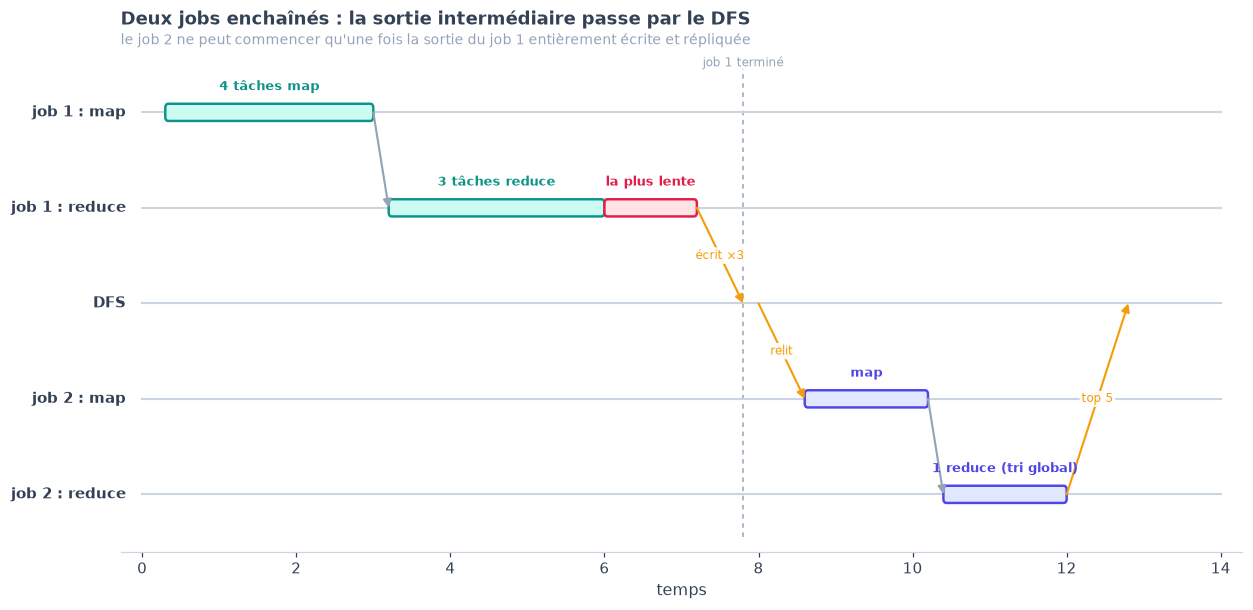

In [9]:
st_ = SpaceTime(["job 1 : map", "job 1 : reduce", "DFS", "job 2 : map", "job 2 : reduce"], t_max=14, width=11.5,
                title="Deux jobs enchaînés : la sortie intermédiaire passe par le DFS",
                subtitle="le job 2 ne peut commencer qu'une fois la sortie du job 1 entièrement écrite et répliquée")
st_.op("job 1 : map", 0.3, 3.0, "4 tâches map", color=TEAL)
st_.op("job 1 : reduce", 3.2, 6.0, "3 tâches reduce", color=TEAL)
st_.op("job 1 : reduce", 6.0, 7.2, "la plus lente", color=ROSE)
st_.msg("job 1 : map", 3.0, "job 1 : reduce", 3.2, "", color=GRAY)
st_.msg("job 1 : reduce", 7.2, "DFS", 7.8, "écrit ×3", color=AMBER)
st_.msg("DFS", 8.0, "job 2 : map", 8.6, "relit", color=AMBER)
st_.op("job 2 : map", 8.6, 10.2, "map", color=INDIGO)
st_.msg("job 2 : map", 10.2, "job 2 : reduce", 10.4, "", color=GRAY)
st_.op("job 2 : reduce", 10.4, 12.0, "1 reduce (tri global)", color=INDIGO)
st_.msg("job 2 : reduce", 12.0, "DFS", 12.8, "top 5", color=AMBER)
st_.vline(7.8, "job 1 terminé")
st_.show()

Les workflows réels comptent des dizaines de jobs ainsi chaînés ; comme écrire des jobs MapReduce à la main est laborieux, des outils de plus haut niveau (Pig, Hive, Cascading, Crunch, FlumeJava) génèrent automatiquement ces chaînes de jobs à partir d'une description plus abstraite (cours 4).

> **À retenir.** Un job MapReduce = un tri. Un calcul qui demande plusieurs
> regroupements devient une chaîne de jobs, dont chaque sortie intermédiaire est
> entièrement écrite (et répliquée) dans le DFS avant que le suivant ne démarre.

## 4. Jointures et regroupements côté reduce (section *Reduce-Side Joins and Grouping*)

**Le besoin.** D'un côté, un journal d'**événements d'activité** (*clickstream*) : quel
utilisateur connecté a vu quelle page, et quand. De l'autre, la **base des
utilisateurs**, avec leur date de naissance. Question : quelles pages plaisent aux jeunes,
lesquelles aux plus âgés ? Il faut **joindre** les deux sur l'identifiant
d'utilisateur. Dans le vocabulaire des entrepôts de données (chapitre 3), le
journal est la table de faits et les utilisateurs une dimension.

**La mauvaise idée** serait d'interroger la base des utilisateurs pour chaque événement :
un aller-retour réseau par enregistrement, une base distante écrasée par la charge, et
un résultat qui dépend du moment de l'exécution si la base change entre-temps (le job
n'est plus déterministe). On prend plutôt une **copie** de la base (un export, dans le
DFS) et on joint les deux fichiers dans le même job.

**La jointure tri-fusion côté reduce.** Deux mappeurs : l'un émet, pour chaque événement,
(identifiant, URL) ; l'autre, pour chaque utilisateur, (identifiant, date de naissance).
Le shuffle réunit chez le même réducteur toutes les valeurs d'un même identifiant. Mieux,
avec un **tri secondaire** (*secondary sort*), on fait en sorte que le réducteur voie
d'abord l'enregistrement utilisateur, puis les événements dans l'ordre chronologique : la
clé de tri est (identifiant, 0, 0) pour l'utilisateur et (identifiant, 1, horodatage)
pour un événement, mais on **partitionne et on groupe** sur l'identifiant seul
(paramètre `group_by`). Le réducteur garde la date de naissance dans une variable et
parcourt les événements : un seul utilisateur en mémoire à la fois, aucune requête réseau.

In [10]:
users = B.make_users(20_000, seed=3)
events = B.make_events(300_000, 20_000, n_urls=40, s_url=0.9, seed=4)
# l'âge influence les pages vues : les plus jeunes préfèrent les premières pages, et
# inversement (pour que la jointure révèle quelque chose)
rng = np.random.default_rng(5)
naissance = {u["user_id"]: u["birth"] for u in users}
for e in events:
    if rng.random() < 0.35:
        age = 2022 - naissance[e["user_id"]]
        e["url"] = f"/page/{int(np.clip(rng.normal((age - 18) / 2.2, 4), 0, 39))}"


def mappeur_jointure(rec):
    if "birth" in rec:
        yield (rec["user_id"], 0, 0), rec["birth"]            # l'utilisateur d'abord
    else:
        yield (rec["user_id"], 1, rec["ts"]), rec["url"]      # puis ses événements, par date


def reducteur_jointure(user_id, valeurs):
    naissance_u = next(valeurs)                               # premier : la date de naissance
    if not isinstance(naissance_u, int):                      # utilisateur absent : on ignore
        return
    for url in valeurs:
        yield [url, naissance_u]


ent = [users[i::2] for i in range(2)] + [events[i::4] for i in range(4)]
joint, stj = B.run_mapreduce(ent, mappeur_jointure, reducteur_jointure, n_reducers=4, group_by=lambda k: k[0])
print(f"{stj.map_input_records:,} enregistrements lus (utilisateurs + événements), "
      f"{stj.reduce_groups:,} groupes, {stj.reduce_output_records:,} événements enrichis".replace(",", " "))
pd.DataFrame([r for r in joint[0][:5]], columns=["URL", "année de naissance"])

320 000 enregistrements lus (utilisateurs + événements)  20 000 groupes  300 000 événements enrichis


,URL,année de naissance
0,/page/10,1982
1,/page/32,1982
2,/page/27,1982
3,/page/0,1982
4,/page/2,1982


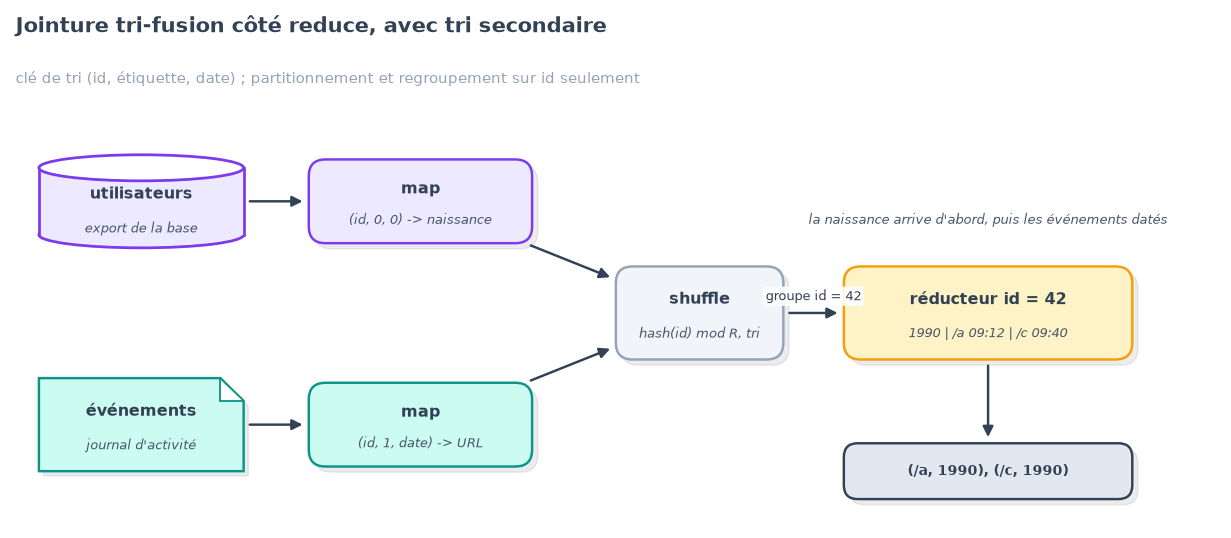

In [11]:
d = Diagram(13, 4.6, title="Jointure tri-fusion côté reduce, avec tri secondaire",
            subtitle="clé de tri (id, étiquette, date) ; partitionnement et regroupement sur id seulement")
d.box("u", 1.4, 3.5, "utilisateurs", sub="export de la base", color=VIOLET, kind="db", w=2.2, h=1.0)
d.box("e", 1.4, 1.1, "événements", sub="journal d'activité", color=TEAL, kind="doc", w=2.2, h=1.0)
d.box("mu", 4.4, 3.5, "map", sub="(id, 0, 0) -> naissance", color=VIOLET, w=2.4)
d.box("me", 4.4, 1.1, "map", sub="(id, 1, date) -> URL", color=TEAL, w=2.4)
d.box("sh", 7.4, 2.3, "shuffle", sub="hash(id) mod R, tri", color=GRAY, w=1.8, h=1.0)
d.box("r", 10.5, 2.3, "réducteur id = 42", sub="1990 | /a 09:12 | /c 09:40", color=AMBER, w=3.1, h=1.0)
d.box("o", 10.5, 0.6, "(/a, 1990), (/c, 1990)", color=SLATE, w=3.1, h=0.6, fontsize=9)
d.arrow("u", "mu", ""); d.arrow("e", "me", "")
d.arrow("mu", "sh", ""); d.arrow("me", "sh", "")
d.arrow("sh", "r", "groupe id = 42")
d.arrow("r", "o", "")
d.note(10.5, 3.3, "la naissance arrive d'abord, puis les événements datés", fontsize=8.5)
d.show()

**Le regroupement.** Le job suivant du workflow calcule, pour chaque URL, la
distribution des âges des visiteurs : on **shuffle sur l'URL**, et le réducteur
incrémente un compteur par tranche d'âge. C'est un `GROUP BY` avec agrégation, que le
shuffle rend aussi simple qu'un parcours séquentiel.

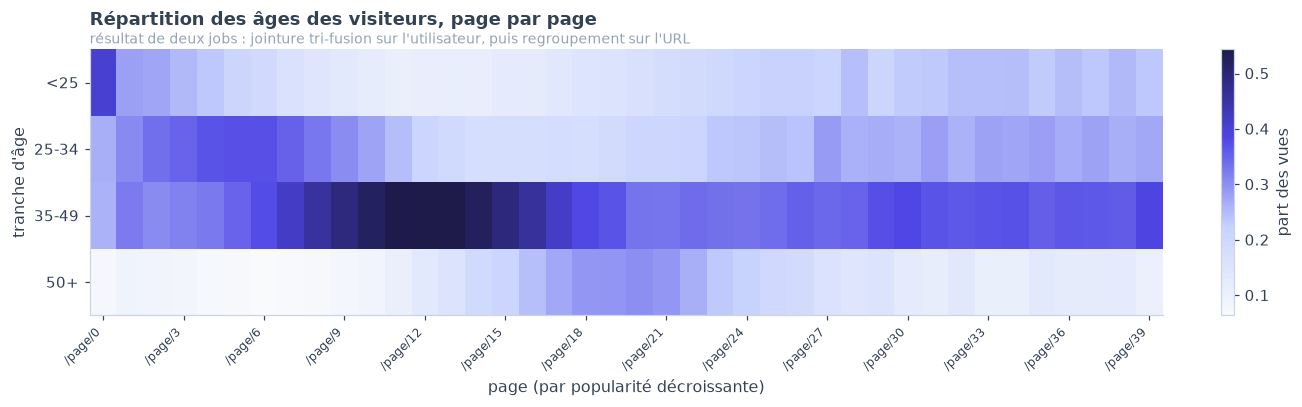

In [12]:
def mappeur_age(rec):
    url, naissance_u = rec
    age = 2022 - naissance_u
    tranche = "<25" if age < 25 else "25-34" if age < 35 else "35-49" if age < 50 else "50+"
    yield url, tranche


def reducteur_distribution(url, tranches):
    c = Counter(tranches)
    yield [url, c.get("<25", 0), c.get("25-34", 0), c.get("35-49", 0), c.get("50+", 0)]


dist, _ = B.run_mapreduce(joint, mappeur_age, reducteur_distribution, n_reducers=3)
D = pd.DataFrame([r for o in dist for r in o], columns=["url", "<25", "25-34", "35-49", "50+"])
D["n"] = D[["<25", "25-34", "35-49", "50+"]].sum(axis=1)
D["num"] = D.url.str.extract(r"(\d+)").astype(int)
D = D.sort_values("num").set_index("url")
parts = D[["<25", "25-34", "35-49", "50+"]].div(D.n, axis=0)
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(parts.T.values, aspect="auto", cmap="ddia_seq")
ax.set_yticks(range(4)); ax.set_yticklabels(parts.columns)
ax.set_xticks(range(0, len(parts), 3)); ax.set_xticklabels(parts.index[::3], rotation=45, ha="right", fontsize=8)
ax.grid(False)
plt.colorbar(im, ax=ax, label="part des vues", fraction=0.025)
ax.set_title("Répartition des âges des visiteurs, page par page")
subtitle(ax, "résultat de deux jobs : jointure tri-fusion sur l'utilisateur, puis regroupement sur l'URL")
ax.set_xlabel("page (par popularité décroissante)"); ax.set_ylabel("tranche d'âge")
plt.tight_layout(); plt.show()

La jointure fait apparaître ce que chaque table seule cachait : la page 0 est
surreprésentée chez les moins de 25 ans, les pages 3 à 7 chez les 25-34 ans, les pages
10 à 15 chez les 35-49 ans et les pages 16 à 22 chez les plus de 50 ans (la tranche la
plus rare, d'où ses teintes claires).

> **À retenir.** La jointure côté reduce émet les deux tables avec la clé de jointure ;
> le shuffle rassemble chaque clé chez un réducteur, et le tri secondaire y fait arriver
> l'enregistrement de dimension en premier. Le réducteur n'a qu'une entité en mémoire et
> ne fait aucune requête réseau ; c'est une **jointure tri-fusion** (*sort-merge join*).